# Challenge 4: Quantum Correlation Switch

**Objective:** Create two quantum circuits that produce correlated and opposite measurement outcomes.

**Prediction:**
- Part A: Outcomes `00` and `11` will dominate.
- Part B: Outcomes `01` and `10` will dominate.

In [1]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

Part A Circuit:
     ┌───┐     ┌─┐   
q_0: ┤ H ├──■──┤M├───
     └───┘┌─┴─┐└╥┘┌─┐
q_1: ─────┤ X ├─╫─┤M├
          └───┘ ║ └╥┘
c: 2/═══════════╩══╩═
                0  1 
Part A Results: {'11': 50, '00': 50}


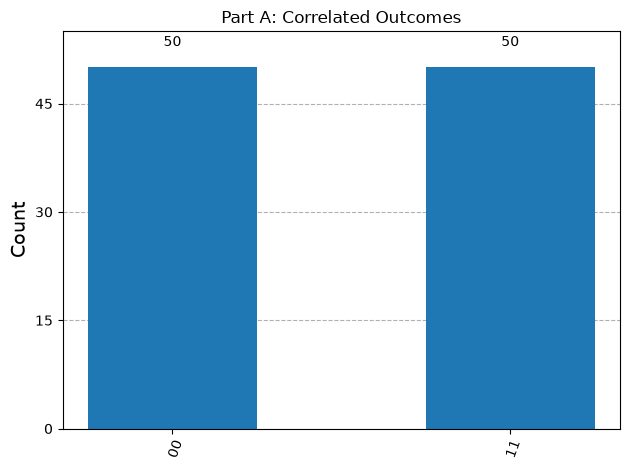

In [2]:
qc_a = QuantumCircuit(2, 2)

qc_a.h(0)
qc_a.cx(0, 1)
qc_a.measure([0, 1], [0, 1])

print("Part A Circuit:")
print(qc_a.draw())

simulator = AerSimulator()
compiled_a = transpile(qc_a, simulator)

result_a = simulator.run(compiled_a, shots=100).result()
counts_a = result_a.get_counts()

print("Part A Results:", counts_a)
display(plot_histogram(counts_a, title="Part A: Correlated Outcomes"))

Part B Circuit:
     ┌───┐          ┌─┐   
q_0: ┤ H ├──■───────┤M├───
     └───┘┌─┴─┐┌───┐└╥┘┌─┐
q_1: ─────┤ X ├┤ X ├─╫─┤M├
          └───┘└───┘ ║ └╥┘
c: 2/════════════════╩══╩═
                     0  1 
Part B Results: {'10': 42, '01': 58}


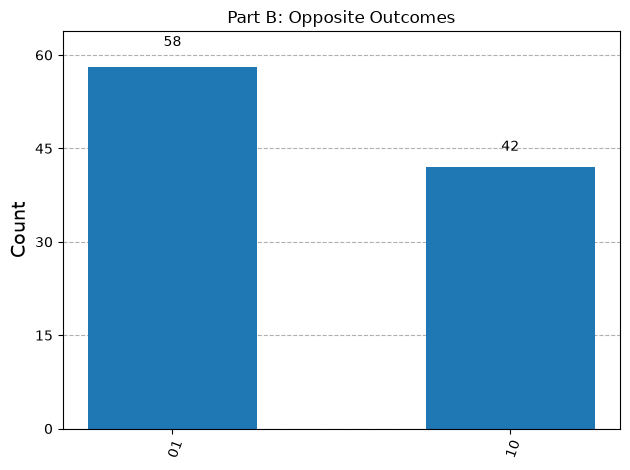

In [3]:
qc_b = QuantumCircuit(2, 2)

qc_b.h(0)
qc_b.cx(0, 1)
qc_b.x(1)
qc_b.measure([0, 1], [0, 1])

print("Part B Circuit:")
print(qc_b.draw())

compiled_b = transpile(qc_b, simulator)

result_b = simulator.run(compiled_b, shots=100).result()
counts_b = result_b.get_counts()

print("Part B Results:", counts_b)
display(plot_histogram(counts_b, title="Part B: Opposite Outcomes"))

In [4]:
print("Part A total shots:", sum(counts_a.values()))
print("Part B total shots:", sum(counts_b.values()))

assert sum(counts_a.values()) == 100
assert sum(counts_b.values()) == 100

print("\nBoth experiments passed the 100-shot verification!")

Part A total shots: 100
Part B total shots: 100

Both experiments passed the 100-shot verification!


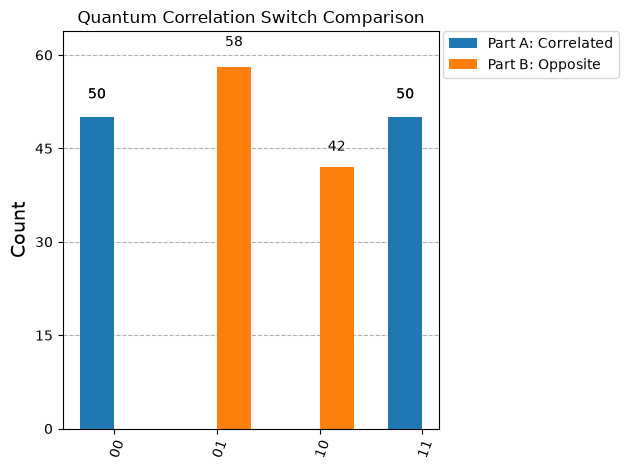

In [5]:
display(plot_histogram(
    [counts_a, counts_b],
    legend=["Part A: Correlated", "Part B: Opposite"],
    title="Quantum Correlation Switch Comparison"
))


Part A:
The Hadamard gate and CNOT gate create a Bell state.
The dominant measurement outcomes are 00 and 11.

Part B:
An X gate is added to the second qubit.
This flips that qubit, changing the dominant outcomes
to 01 and 10.

Comparison:
Part A produces correlated outcomes, while Part B
produces opposite outcomes.

The X gate changes the measurement relationship by
flipping one qubit. Ideally, only two outcomes appear
in each experiment, with approximately 50 counts each
out of 100 shots.
